In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

sns.set_theme(style = "whitegrid")

df = pd.read_csv("/Users/laralaird/Downloads/BDAA/keplerObjectsOfInterest/KeplerObjectData.csv", comment = "#", usecols = ["koi_disposition", "koi_steff", "koi_slogg", "koi_srad", "koi_kepmag", "koi_depth", "koi_prad"])

df = df.rename(columns = {"koi_disposition" : "KOI_Confirmation_Status", "koi_steff" : "Stellar_Effective_Temperature", "koi_slogg" : "Stellar_Surface_Gravity", "koi_srad" : "Stellar_Radius", "koi_kepmag" : "Stellar_Magnitude", "koi_depth" : "Transit_Depth", "koi_prad" : "Planet_Radius"})


print("Missing values before:")
print(df.isna().sum())

print("Shape before:", df.shape)

df = df.dropna()

print("\nMissing values after dropna:")
print(df.isna().sum())

print("Shape after:", df.shape)

colors = {
    "CONFIRMED": "#3C754E", 
    "CANDIDATE": "#FED000",
    "FALSE POSITIVE": "#a92121"
}

Missing values before:
KOI_Confirmation_Status            0
Transit_Depth                    363
Planet_Radius                    363
Stellar_Effective_Temperature    363
Stellar_Surface_Gravity          363
Stellar_Radius                   363
Stellar_Magnitude                  1
dtype: int64
Shape before: (9564, 7)

Missing values after dropna:
KOI_Confirmation_Status          0
Transit_Depth                    0
Planet_Radius                    0
Stellar_Effective_Temperature    0
Stellar_Surface_Gravity          0
Stellar_Radius                   0
Stellar_Magnitude                0
dtype: int64
Shape after: (9200, 7)


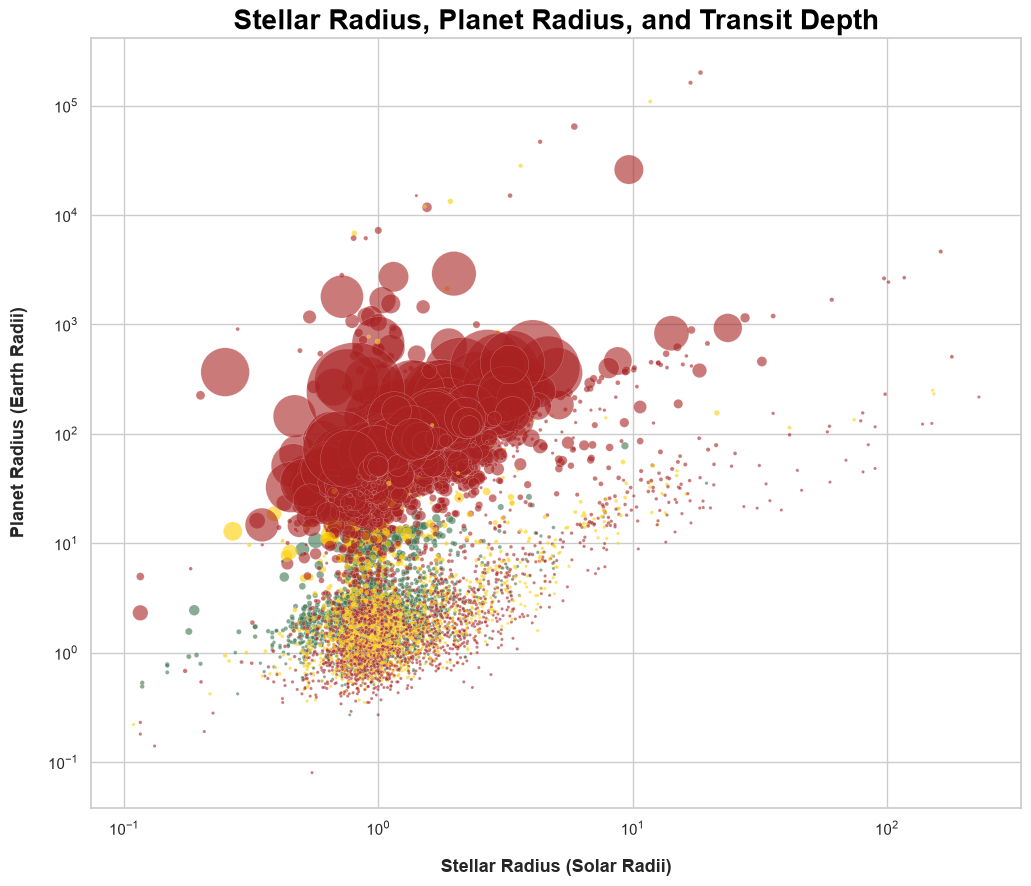

In [2]:
plt.figure(figsize = (12, 10))

sns.scatterplot(
    data = df,
    x = "Stellar_Radius",
    y = "Planet_Radius",
    size = "Transit_Depth",
    hue = "KOI_Confirmation_Status",
    sizes = (5, 5000),
    alpha = 0.6,
    palette = colors,
)

plt.legend().remove()
#I printed the legend separately to fit the poster better

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Stellar Radius (Solar Radii)", labelpad = 15, fontsize = 13, fontweight = "bold")
plt.ylabel("Planet Radius (Earth Radii)", labelpad = 15, fontsize = 13, fontweight = "bold")

plt.title(
    "Stellar Radius, Planet Radius, and Transit Depth",
    fontsize = 20,
    fontweight = "bold",
    color = "black"
)

plt.show()

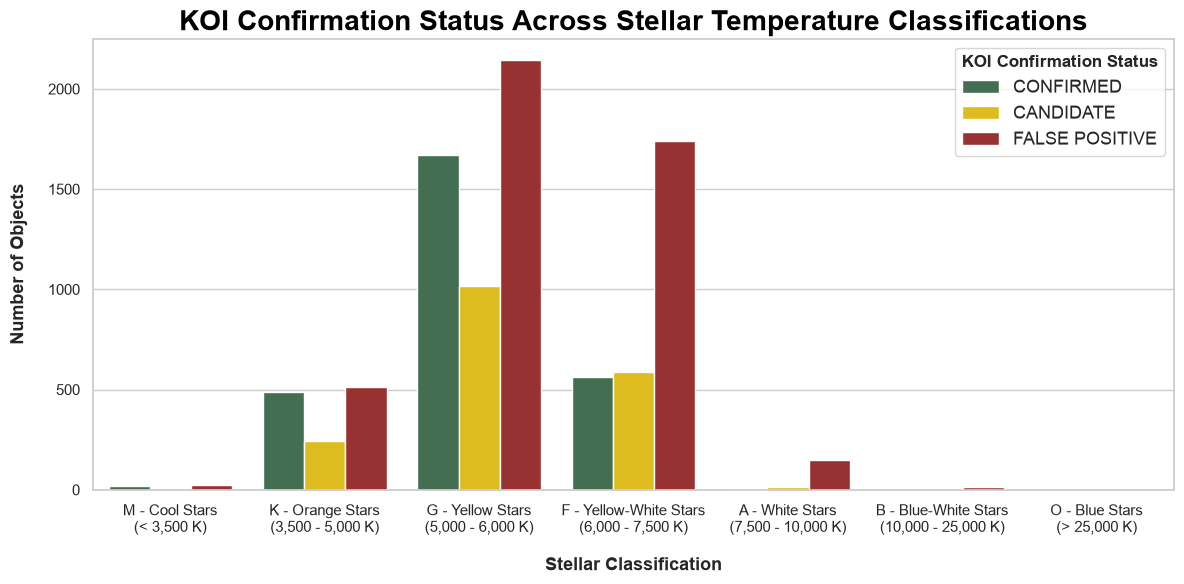

Chi-Square Statistic: 409.95446911020207
P-Value: 7.155592181383249e-82
Degrees of Freedom: 10


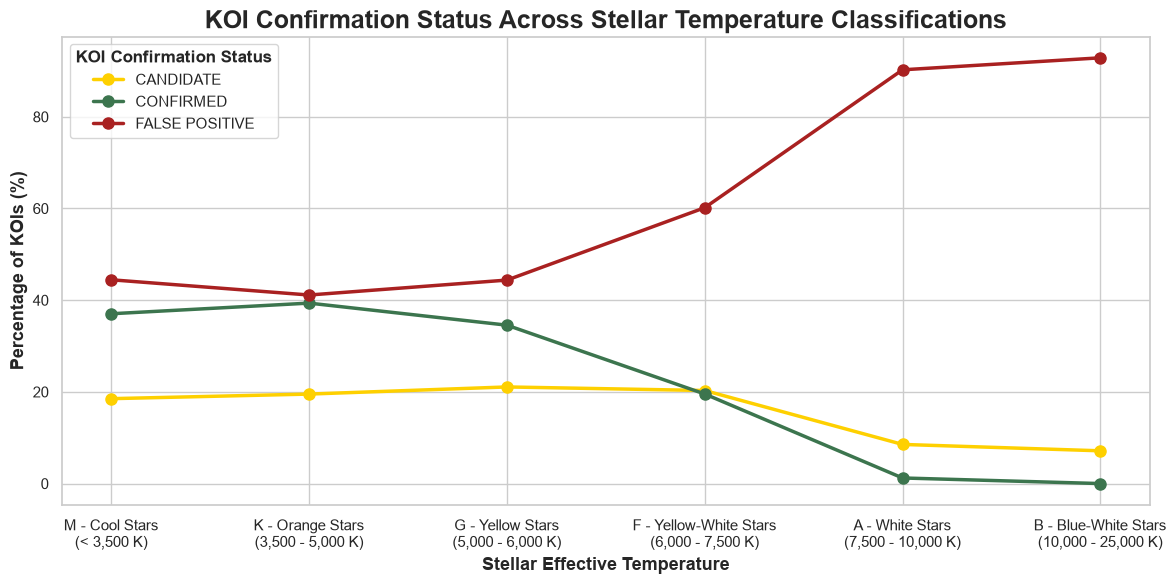

In [3]:
Stellar_Temp_Bin_Edges = [0, 3500, 5000, 6000, 7500, 10000, 25000, float("inf")]

Stellar_Temp_Bin_Labels = [
    "M - Cool Stars\n(< 3,500 K)",
    "K - Orange Stars\n(3,500 - 5,000 K)",
    "G - Yellow Stars\n(5,000 - 6,000 K)",
    "F - Yellow-White Stars\n(6,000 - 7,500 K)",
    "A - White Stars\n(7,500 - 10,000 K)",
    "B - Blue-White Stars\n(10,000 - 25,000 K)",
    "O - Blue Stars\n(> 25,000 K)"
]

df["Stellar_Temp_Bins"] = pd.cut(
    df["Stellar_Effective_Temperature"],
    bins = Stellar_Temp_Bin_Edges,
    labels = Stellar_Temp_Bin_Labels
)

plt.figure(figsize=(12, 6))

sns.countplot(
    data = df,
    x = "Stellar_Temp_Bins",
    hue = "KOI_Confirmation_Status",
    palette = colors
)

legend = plt.legend(title = "KOI Confirmation Status", fontsize = 13)
legend.get_title().set_fontweight("bold")

plt.xlabel("Stellar Classification", labelpad = 15, fontsize = 13, fontweight = "bold")
plt.ylabel("Number of Objects", labelpad = 15, fontsize = 13, fontweight = "bold")
plt.title(
    "KOI Confirmation Status Across Stellar Temperature Classifications",
    fontsize = 20,
    fontweight = "bold",
    color = "black"
)

plt.tight_layout()
plt.show()

temperature_percentages = pd.crosstab(
    df["Stellar_Temp_Bins"],
    df["KOI_Confirmation_Status"],
    normalize = "index"
) * 100

temperature_percentages.plot(
    kind = "line",
    figsize = (12, 6),
    color = colors,
    marker = "o",
    linewidth = 2.5,
    markersize = 8,
)

plt.xlabel("Stellar Effective Temperature", fontsize = 13, fontweight = "bold")
plt.ylabel("Percentage of KOIs (%)", fontsize = 13, fontweight = "bold")

plt.title(
    "KOI Confirmation Status Across Stellar Temperature Classifications",
    fontsize = 18,
    fontweight = "bold"
)

legend = plt.legend(title="KOI Confirmation Status", fontsize = 11)
legend.get_title().set_fontweight("bold")

temperature_table = pd.crosstab(
    df["Stellar_Temp_Bins"],
    df["KOI_Confirmation_Status"]
)

chi2, p_value, dof, expected = chi2_contingency(temperature_table)

print("Chi-Square Statistic:", chi2)
print("P-Value:", p_value)
print("Degrees of Freedom:", dof)

plt.tight_layout()
plt.show()

#stellar classification source: https://lweb.cfa.harvard.edu/~pberlind/atlas/htmls/note.html

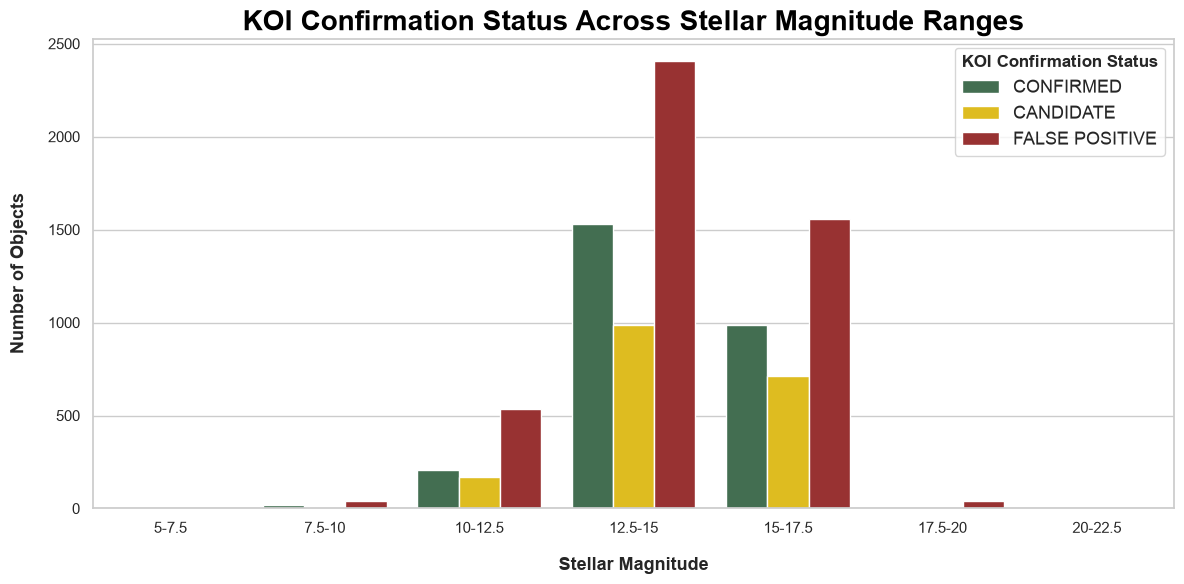

Chi-Square Statistic: 87.28862295007569
P-Value: 1.64983839012654e-13
Degrees of Freedom: 12


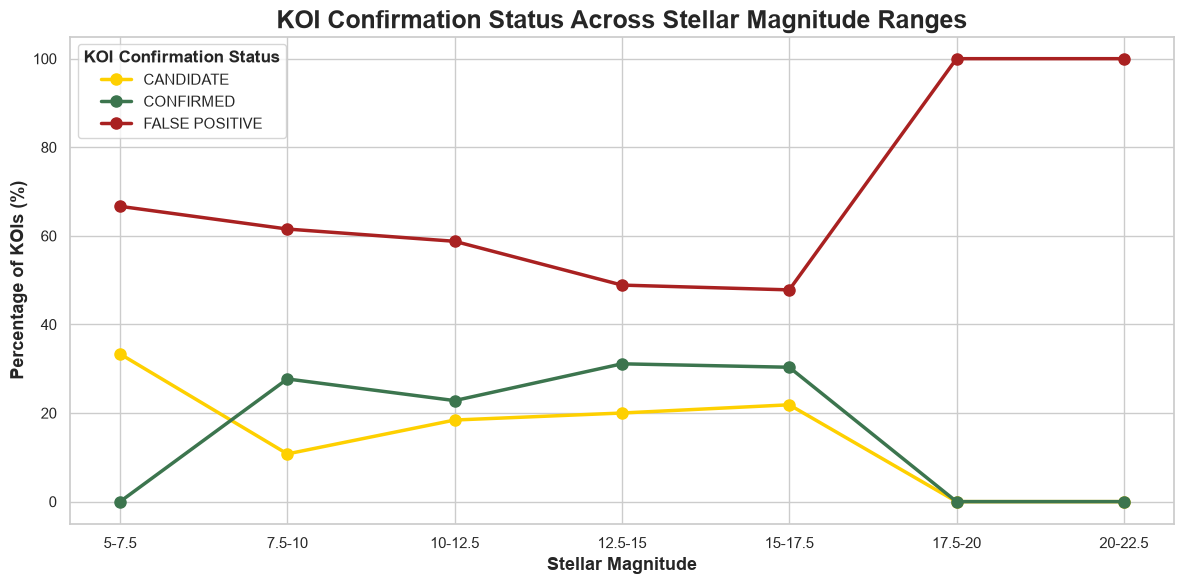

In [4]:
Stellar_Mag_Bin_Edges = [5, 7.5, 10, 12.5, 15, 17.5, 20, 22.5]
Stellar_Mag_Bin_Labels = ["5-7.5", "7.5-10", "10-12.5", "12.5-15", "15-17.5", "17.5-20", "20-22.5"]

df["Stellar_Mag_Bins"] = pd.cut(df["Stellar_Magnitude"], bins = Stellar_Mag_Bin_Edges, labels = Stellar_Mag_Bin_Labels)

plt.figure(figsize = (12, 6))

sns.countplot(
    data = df,
    x = "Stellar_Mag_Bins",
    hue = "KOI_Confirmation_Status",
    palette = colors
)

legend = plt.legend(title = "KOI Confirmation Status", fontsize = 13)
legend.get_title().set_fontweight("bold")

plt.xlabel("Stellar Magnitude", labelpad = 15, fontsize = 13, fontweight = "bold")
plt.ylabel("Number of Objects", labelpad = 15, fontsize = 13, fontweight = "bold")
plt.title(
    "KOI Confirmation Status Across Stellar Magnitude Ranges",
    fontsize = 20,
    fontweight = "bold",
    color = "black"
)

plt.tight_layout()
plt.show()

magnitude_percentages = pd.crosstab(
    df["Stellar_Mag_Bins"],
    df["KOI_Confirmation_Status"],
    normalize = "index"
) * 100

magnitude_percentages.plot(
    kind = "line",
    figsize = (12, 6),
    color = colors,
    marker = "o",
    linewidth = 2.5,
    markersize = 8,
)

plt.xlabel("Stellar Magnitude", fontsize = 13, fontweight = "bold")
plt.ylabel("Percentage of KOIs (%)", fontsize = 13, fontweight = "bold")

plt.title(
    "KOI Confirmation Status Across Stellar Magnitude Ranges",
    fontsize = 18,
    fontweight = "bold"
)

legend = plt.legend(title = "KOI Confirmation Status", fontsize = 11)
legend.get_title().set_fontweight("bold")

magnitude_table = pd.crosstab(
    df["Stellar_Mag_Bins"],
    df["KOI_Confirmation_Status"]
)

chi2, p_value, dof, expected = chi2_contingency(magnitude_table)

print("Chi-Square Statistic:", chi2)
print("P-Value:", p_value)
print("Degrees of Freedom:", dof)

plt.tight_layout()
plt.show()

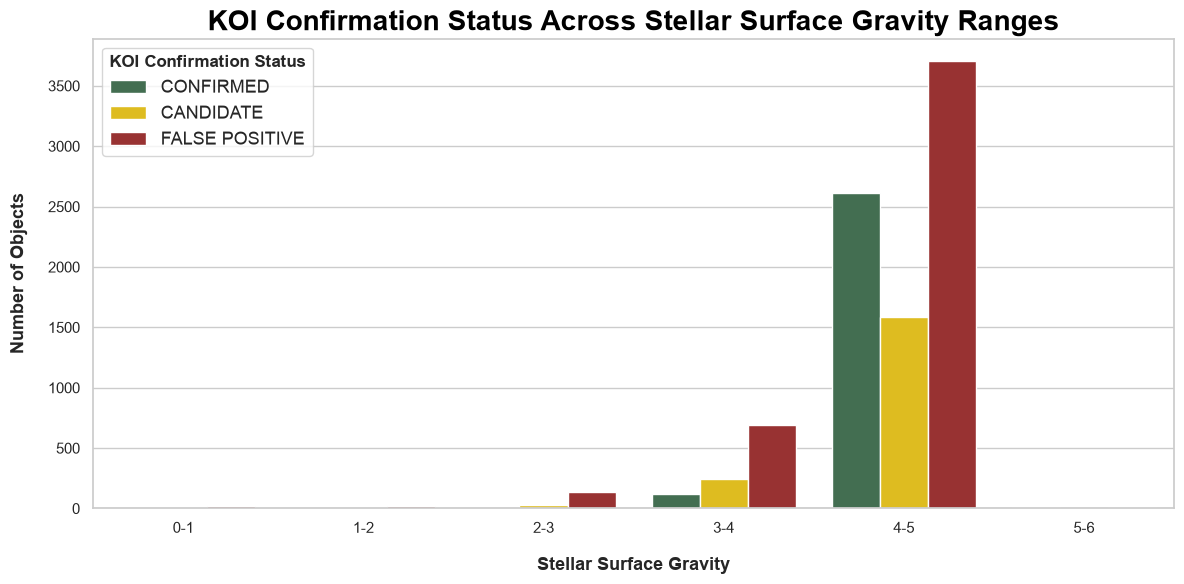

Chi-Square Statistic: 317.72113865335854
P-Value: 2.7706925611455126e-62
Degrees of Freedom: 10


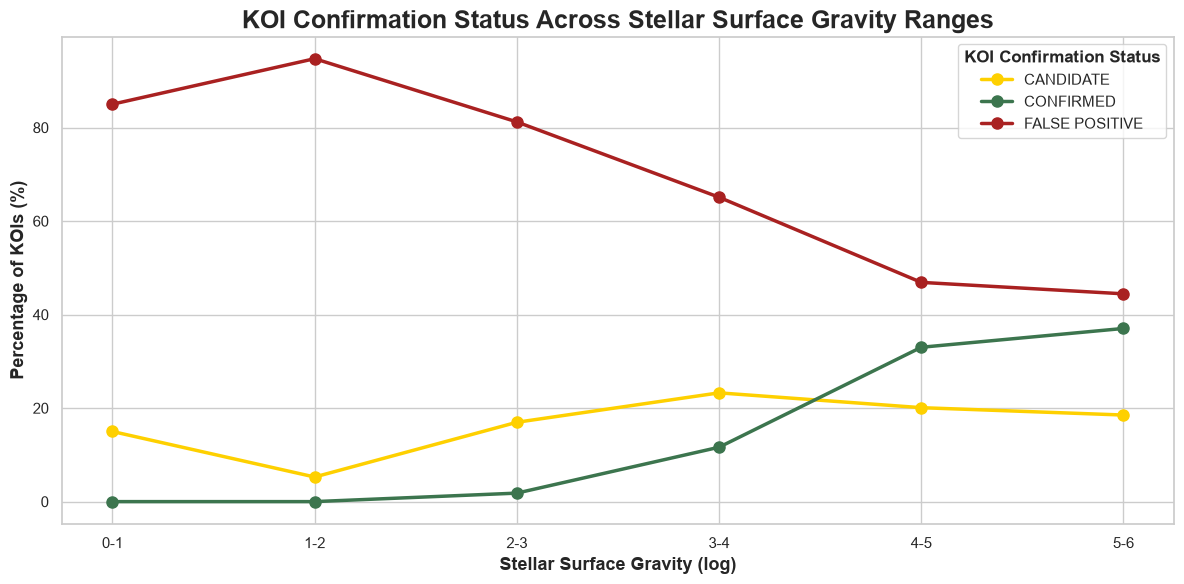

In [5]:
Stellar_Grav_Bin_Edges = [0, 1, 2, 3, 4, 5, 6]
Stellar_Grav_Bin_Labels = ["0-1", "1-2", "2-3", "3-4", "4-5", "5-6"]

df["Stellar_Grav_Bins"] = pd.cut(df["Stellar_Surface_Gravity"], bins = Stellar_Grav_Bin_Edges, labels = Stellar_Grav_Bin_Labels)

plt.figure(figsize = (12, 6))

sns.countplot(
    data = df,
    x = "Stellar_Grav_Bins",
    hue = "KOI_Confirmation_Status",
    palette = colors
)

legend = plt.legend(title="KOI Confirmation Status", fontsize = 13)
legend.get_title().set_fontweight("bold")

plt.xlabel("Stellar Surface Gravity", labelpad = 15, fontsize = 13, fontweight = "bold")
plt.ylabel("Number of Objects", labelpad = 15, fontsize = 13, fontweight = "bold")
plt.title(
    "KOI Confirmation Status Across Stellar Surface Gravity Ranges",
    fontsize = 20,
    fontweight = "bold",
    color = "black"
)

plt.tight_layout()
plt.show()

gravity_percentages = pd.crosstab(
    df["Stellar_Grav_Bins"],
    df["KOI_Confirmation_Status"],
    normalize = "index"
) * 100

gravity_percentages.plot(
    kind = "line",
    figsize = (12, 6),
    color = colors,
    marker = "o",
    linewidth = 2.5,
    markersize = 8,
)

plt.xlabel("Stellar Surface Gravity (log)", fontsize = 13, fontweight = "bold")
plt.ylabel("Percentage of KOIs (%)", fontsize = 13, fontweight = "bold")

plt.title(
    "KOI Confirmation Status Across Stellar Surface Gravity Ranges",
    fontsize = 18,
    fontweight = "bold"
)

legend = plt.legend(title = "KOI Confirmation Status", fontsize = 11)
legend.get_title().set_fontweight("bold")

gravity_table = pd.crosstab(
    df["Stellar_Grav_Bins"],
    df["KOI_Confirmation_Status"]
)

chi2, p_value, dof, expected = chi2_contingency(gravity_table)

print("Chi-Square Statistic:", chi2)
print("P-Value:", p_value)
print("Degrees of Freedom:", dof)

plt.tight_layout()
plt.show()

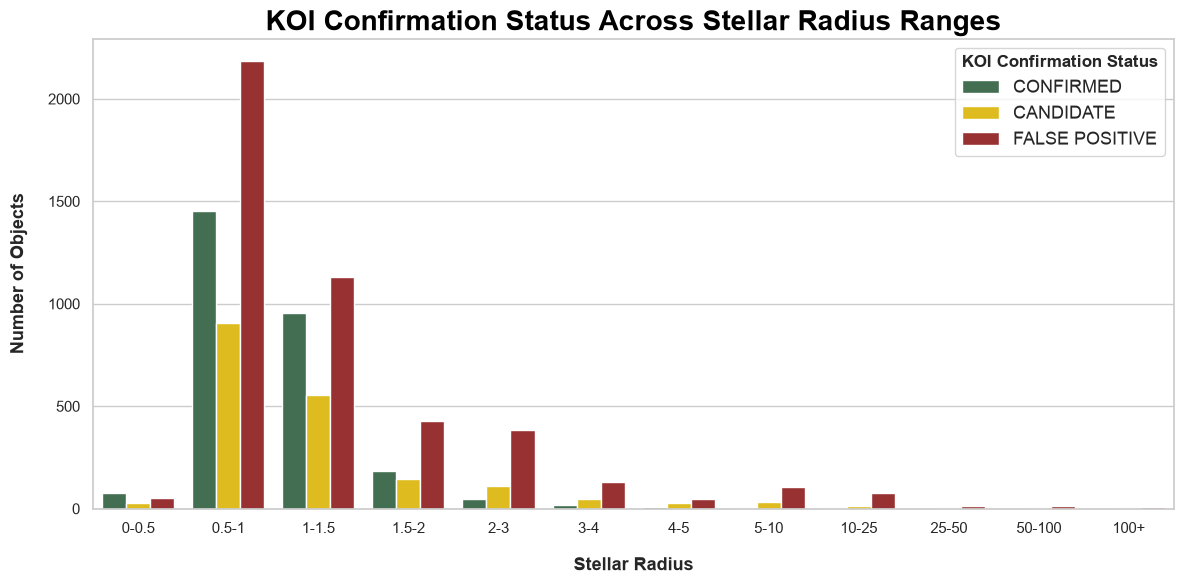

Chi-Square Statistic: 432.89335137724044
P-Value: 6.495183841441987e-78
Degrees of Freedom: 22


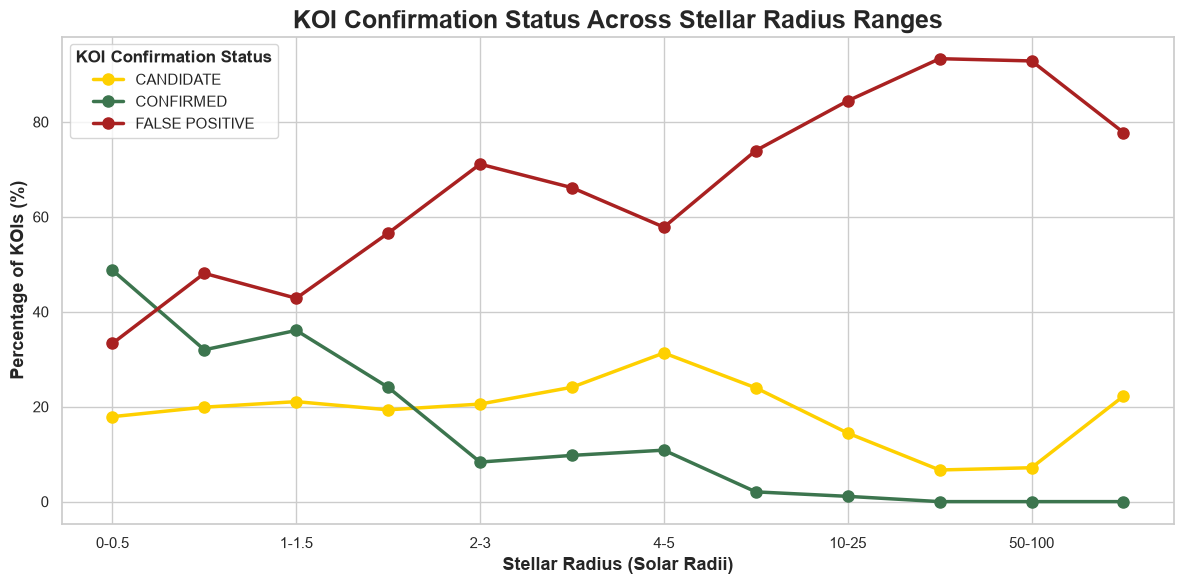

In [6]:
Stellar_Rad_Bin_Edges = [0, 0.5, 1, 1.5, 2, 3, 4, 5, 10, 25, 50, 100, float("inf")]
Stellar_Rad_Bin_Labels = ["0-0.5", "0.5-1", "1-1.5", "1.5-2", "2-3", "3-4", "4-5", "5-10", "10-25", "25-50", "50-100", "100+"]

df["Stellar_Rad_Bins"] = pd.cut(df["Stellar_Radius"], bins = Stellar_Rad_Bin_Edges, labels = Stellar_Rad_Bin_Labels)

plt.figure(figsize = (12, 6))

sns.countplot(
    data = df,
    x = "Stellar_Rad_Bins",
    hue = "KOI_Confirmation_Status",
    palette = colors
)

legend = plt.legend(title="KOI Confirmation Status", fontsize = 13)
legend.get_title().set_fontweight("bold")

plt.xlabel("Stellar Radius", labelpad = 15, fontsize = 13, fontweight = "bold")
plt.ylabel("Number of Objects", labelpad = 15, fontsize = 13, fontweight = "bold")
plt.title(
    "KOI Confirmation Status Across Stellar Radius Ranges",
    fontsize = 20,
    fontweight = "bold",
    color = "black"
)

plt.tight_layout()
plt.show()

radius_percentages = pd.crosstab(
    df["Stellar_Rad_Bins"],
    df["KOI_Confirmation_Status"],
    normalize = "index"
) * 100

radius_percentages.plot(
    kind = "line",
    figsize = (12, 6),
    color = colors,
    marker = "o",
    linewidth = 2.5,
    markersize = 8,
)

plt.xlabel("Stellar Radius (Solar Radii)", fontsize = 13, fontweight = "bold")
plt.ylabel("Percentage of KOIs (%)", fontsize = 13, fontweight = "bold")

plt.title(
    "KOI Confirmation Status Across Stellar Radius Ranges",
    fontsize = 18,
    fontweight = "bold"
)

legend = plt.legend(title = "KOI Confirmation Status", fontsize = 11)
legend.get_title().set_fontweight("bold")

radius_table = pd.crosstab(
    df["Stellar_Rad_Bins"],
    df["KOI_Confirmation_Status"]
)

chi2, p_value, dof, expected = chi2_contingency(radius_table)

print("Chi-Square Statistic:", chi2)
print("P-Value:", p_value)
print("Degrees of Freedom:", dof)

plt.tight_layout()
plt.show()